# Pouring

> Video frame sequences of a cup/container being filled/poured (opaque vs transparent training; separate test videos).

**GT available:**
- Frame-wise LabelMe JSON polygons over `rgb_*.jpg` (e.g., `liquid_mask` shapes)
- Per-frame pixel labels via sidecar `label.png` / `label_viz.png` (+ `label_names.txt`) in test split
- Cup masks (`*_cup_mask.png`) and empty-cup reference frames in training split

In [2]:
from __future__ import annotations

import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path('..') / 'data' / 'pouring'
TEST_ROOT = ROOT / 'pouring_testset_videos'
TRAIN_ROOT = ROOT / 'pouring_training_videos'

assert ROOT.exists(), f'Dataset root not found: {ROOT}'
assert TEST_ROOT.exists(), f'Test split not found: {TEST_ROOT}'
assert TRAIN_ROOT.exists(), f'Training split not found: {TRAIN_ROOT}'

def list_video_dirs(parent: Path):
    return sorted([p for p in parent.iterdir() if p.is_dir() and re.fullmatch(r'video_\d+', p.name)])

test_videos = list_video_dirs(TEST_ROOT)
opaque_videos = list_video_dirs(TRAIN_ROOT / 'opaque')
transparent_videos = list_video_dirs(TRAIN_ROOT / 'transparent')

print(f'Dataset root: {ROOT}')
print(f'Test videos: {len(test_videos)} -> {[v.name for v in test_videos]}')
print(f'Training opaque videos: {len(opaque_videos)}')
print(f'Training transparent videos: {len(transparent_videos)}')

Dataset root: ../data/pouring
Test videos: 4 -> ['video_0', 'video_1', 'video_2', 'video_4']
Training opaque videos: 15
Training transparent videos: 15


## Capability audit across splits

From dataset inspection:

- **Test split** stores frame-wise RGB images plus one JSON annotation per frame.
- Each test frame also has a sidecar folder (e.g., `rgb_30_json`) with `img.png`, `label.png`, `label_viz.png`, and `label_names.txt`.
- **Training split** is organized by material (`opaque` / `transparent`) and contains RGB sequences, empty-cup reference frames, and dedicated cup-mask folders (`video_X_cup_masks`).

Test split per-video coverage (video, rgb_jpg, frame_json, frame_sidecar_dirs):
- ('video_0', 35, 35, 35)
- ('video_1', 32, 32, 32)
- ('video_2', 35, 35, 35)
- ('video_4', 31, 31, 31)

Sidecar file names observed (sampled over test videos):
- img.png         seen_in_sampled_dirs=20
- label.png       seen_in_sampled_dirs=20
- label_names.txt seen_in_sampled_dirs=20
- label_viz.png   seen_in_sampled_dirs=20

Training split summary (first 8 videos each):
opaque -> (video, rgb, empty_cup, cup_masks, mask_dir_exists)
- ('video_0', 147, 50, 197, True)
- ('video_1', 149, 50, 199, True)
- ('video_10', 149, 50, 199, True)
- ('video_11', 148, 50, 198, True)
- ('video_12', 149, 50, 199, True)
- ('video_13', 148, 50, 198, True)
- ('video_14', 149, 50, 199, True)
- ('video_2', 150, 50, 200, True)
transparent -> (video, rgb, empty_cup, cup_masks, mask_dir_exists)
- ('video_0', 150, 50, 200, True)
- ('video_1', 150, 50, 200, True)
- ('video_10', 150, 50, 200, True)
- ('video_11', 147, 50, 197, True)


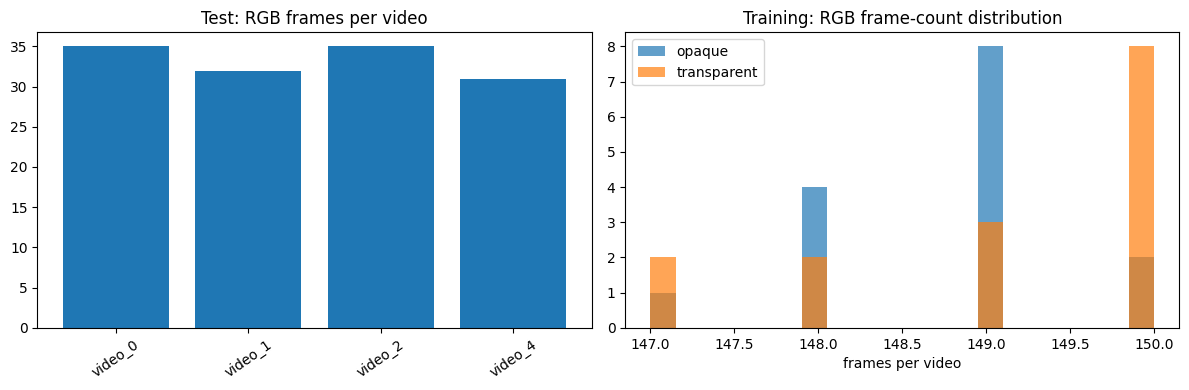

In [3]:
def count_files(path: Path, pattern: str) -> int:
    return len(list(path.glob(pattern)))

test_rows = []
sidecar_presence = Counter()

for v in test_videos:
    n_rgb = count_files(v, 'rgb_*.jpg')
    n_json = count_files(v, 'rgb_*.json')
    sidecar_dirs = sorted(v.glob('rgb_*_json'))
    n_sidecar = len(sidecar_dirs)

    for sd in sidecar_dirs[:5]:
        for f in sd.iterdir():
            if f.is_file():
                sidecar_presence[f.name] += 1

    test_rows.append((v.name, n_rgb, n_json, n_sidecar))

print('Test split per-video coverage (video, rgb_jpg, frame_json, frame_sidecar_dirs):')
for row in test_rows:
    print('-', row)

print('\nSidecar file names observed (sampled over test videos):')
for k, c in sorted(sidecar_presence.items()):
    print(f'- {k:<15} seen_in_sampled_dirs={c}')

def training_summary(material: str):
    base = TRAIN_ROOT / material
    videos = list_video_dirs(base)
    rows = []
    for v in videos:
        n_rgb = count_files(v, 'rgb_*.jpg')
        n_empty = count_files(v, 'empty_cup_*.jpg')
        cup_mask_dir = base / f'{v.name}_cup_masks'
        n_cup_masks = count_files(cup_mask_dir, '*_cup_mask.png') if cup_mask_dir.exists() else 0
        rows.append((v.name, n_rgb, n_empty, n_cup_masks, cup_mask_dir.exists()))
    return rows

opaque_rows = training_summary('opaque')
transparent_rows = training_summary('transparent')

print('\nTraining split summary (first 8 videos each):')
print('opaque -> (video, rgb, empty_cup, cup_masks, mask_dir_exists)')
for row in opaque_rows[:8]:
    print('-', row)
print('transparent -> (video, rgb, empty_cup, cup_masks, mask_dir_exists)')
for row in transparent_rows[:8]:
    print('-', row)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar([r[0] for r in test_rows], [r[1] for r in test_rows])
axes[0].set_title('Test: RGB frames per video')
axes[0].tick_params(axis='x', rotation=35)

axes[1].hist([r[1] for r in opaque_rows], bins=20, alpha=0.7, label='opaque')
axes[1].hist([r[1] for r in transparent_rows], bins=20, alpha=0.7, label='transparent')
axes[1].set_title('Training: RGB frame-count distribution')
axes[1].set_xlabel('frames per video')
axes[1].legend()

plt.tight_layout()
plt.show()

## Annotation schema and statistics

Test JSON files follow a LabelMe-style schema with polygons over `rgb_*.jpg` images.

The next cell summarizes:

- label vocabulary and shape types,
- polygon complexity (points per shape),
- image size distribution,
- and frame-level annotation counts.

Total test JSON files: 133
Labels:
- liquid_mask: 134

Shape types:
- polygon: 134

Most common image sizes:
- 150x300: 133

Annotations per frame:
- min: 1
- median: 1.0
- max: 2


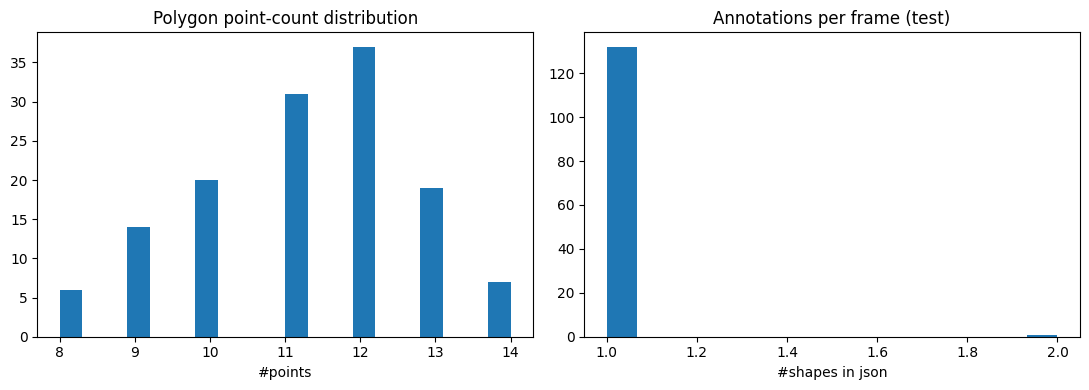

In [4]:
label_counter = Counter()
shape_type_counter = Counter()
points_per_shape = []
image_sizes = Counter()
ann_per_frame = []

json_paths = sorted(TEST_ROOT.glob('video_*/rgb_*.json'))

for p in json_paths:
    try:
        data = json.loads(p.read_text(encoding='utf-8'))
    except Exception:
        continue

    image_sizes[(data.get('imageWidth'), data.get('imageHeight'))] += 1

    shapes = data.get('shapes', [])
    ann_per_frame.append(len(shapes))

    for s in shapes:
        label_counter[s.get('label', '<missing>')] += 1
        shape_type_counter[s.get('shape_type', '<missing>')] += 1
        pts = s.get('points', [])
        points_per_shape.append(len(pts))

print(f'Total test JSON files: {len(json_paths)}')
print('Labels:')
for k, c in label_counter.items():
    print(f'- {k}: {c}')

print('\nShape types:')
for k, c in shape_type_counter.items():
    print(f'- {k}: {c}')

print('\nMost common image sizes:')
for (w, h), c in image_sizes.most_common(5):
    print(f'- {w}x{h}: {c}')

if ann_per_frame:
    arr_ann = np.array(ann_per_frame)
    print('\nAnnotations per frame:')
    print(f'- min: {arr_ann.min()}')
    print(f'- median: {np.median(arr_ann):.1f}')
    print(f'- max: {arr_ann.max()}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(points_per_shape, bins=20)
axes[0].set_title('Polygon point-count distribution')
axes[0].set_xlabel('#points')

axes[1].hist(ann_per_frame, bins=15)
axes[1].set_title('Annotations per frame (test)')
axes[1].set_xlabel('#shapes in json')

plt.tight_layout()
plt.show()

## Multi-frame panel (test split)

Each test video is a sequence of frame datapoints. For each selected frame we show:

- RGB frame,
- sidecar label visualization (`label_viz.png`),
- and raw label image (`label.png`).

This provides a quick frame-by-frame overview of liquid-mask annotations.

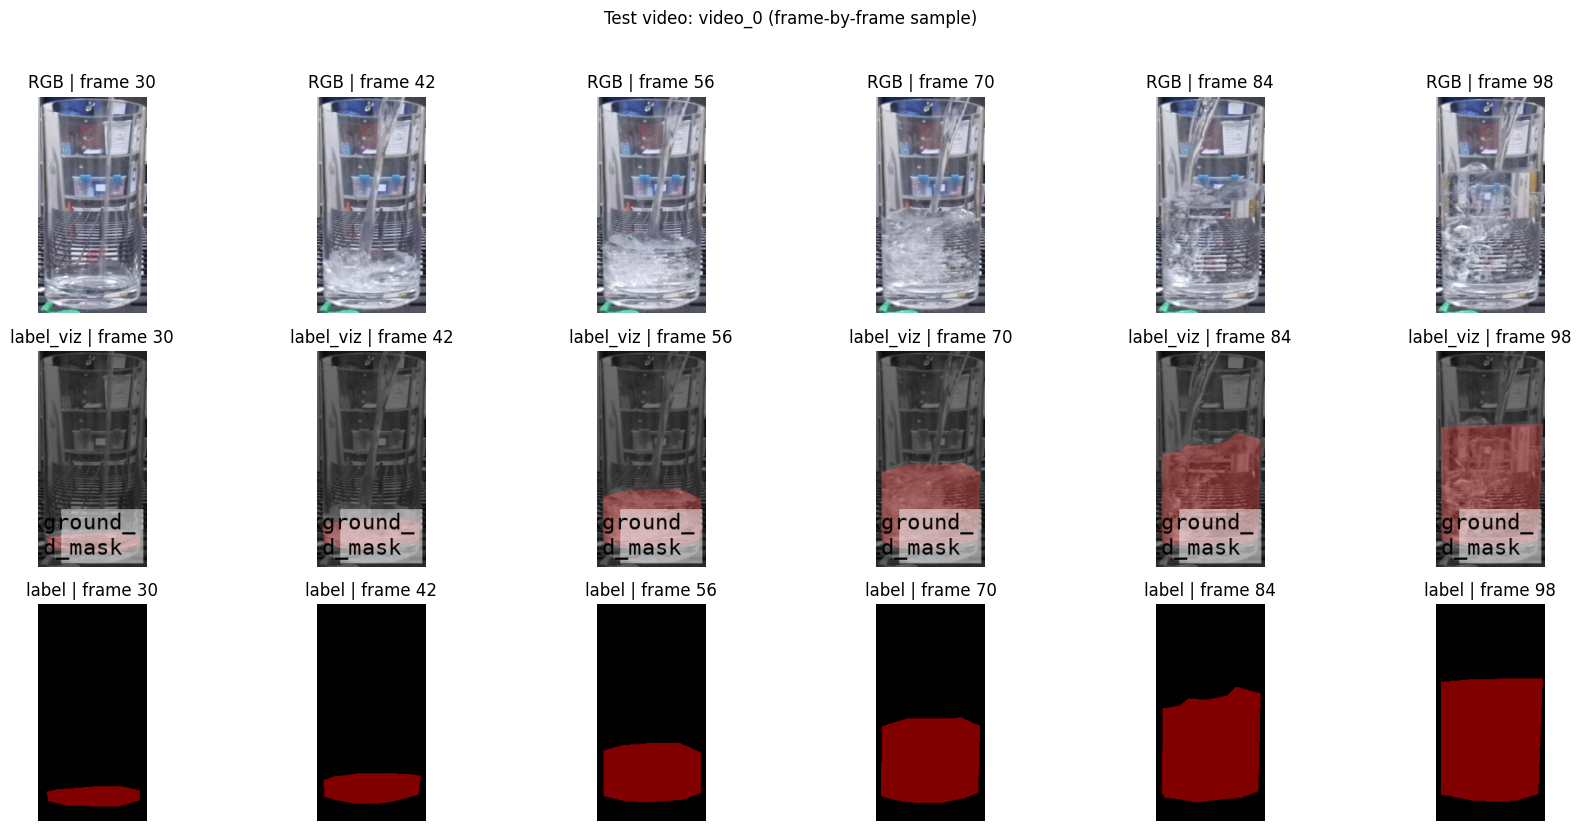

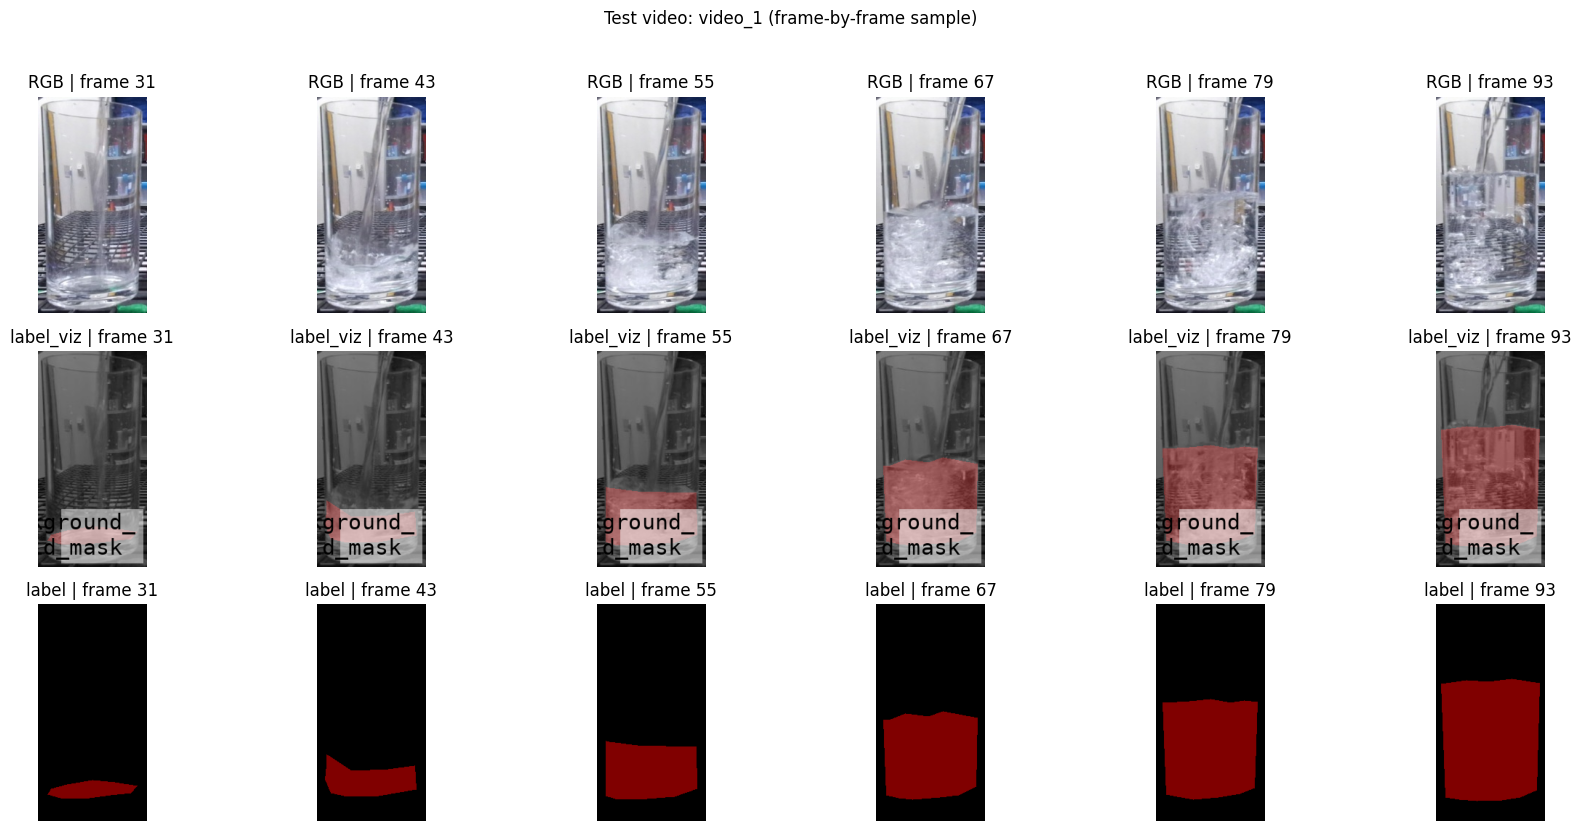

In [5]:
def read_img(path: Path):
    if not path.exists():
        return None
    return plt.imread(path)

def frame_idx_from_name(path: Path) -> int:
    m = re.search(r'rgb_(\d+)', path.stem)
    return int(m.group(1)) if m else -1

def pick_spread(items, n=6):
    if len(items) <= n:
        return items
    idxs = np.linspace(0, len(items) - 1, n, dtype=int)
    return [items[i] for i in idxs]

def show_test_video_frames(video_name: str, n_frames: int = 6):
    video_dir = TEST_ROOT / video_name
    rgb_paths = sorted(video_dir.glob('rgb_*.jpg'), key=frame_idx_from_name)
    selected = pick_spread(rgb_paths, n=n_frames)

    if not selected:
        print(f'No frames found in {video_dir}')
        return

    rows, cols = 3, len(selected)
    fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 2.7 * rows))

    for col, rgb_path in enumerate(selected):
        frame_idx = frame_idx_from_name(rgb_path)
        sidecar = video_dir / f'rgb_{frame_idx}_json'

        rgb = read_img(rgb_path)
        viz = read_img(sidecar / 'label_viz.png')
        lab = read_img(sidecar / 'label.png')

        items = [('RGB', rgb), ('label_viz', viz), ('label', lab)]
        for row, (name, img) in enumerate(items):
            ax = axes[row, col] if cols > 1 else axes[row]
            if img is None:
                ax.text(0.5, 0.5, 'missing', ha='center', va='center')
            elif img.ndim == 2:
                ax.imshow(img, cmap='gray')
            else:
                ax.imshow(img)
            ax.set_title(f'{name} | frame {frame_idx}')
            ax.axis('off')

    fig.suptitle(f'Test video: {video_name} (frame-by-frame sample)', y=1.02)
    plt.tight_layout()
    plt.show()

show_test_video_frames('video_0', n_frames=6)
show_test_video_frames('video_1', n_frames=6)

## Multi-frame panel (training split)

Training videos provide RGB frames and cup masks in paired folders.

The next cell visualizes multiple frames per sample datapoint (video):

- RGB frame
- cup mask (`*_cup_mask.png`)

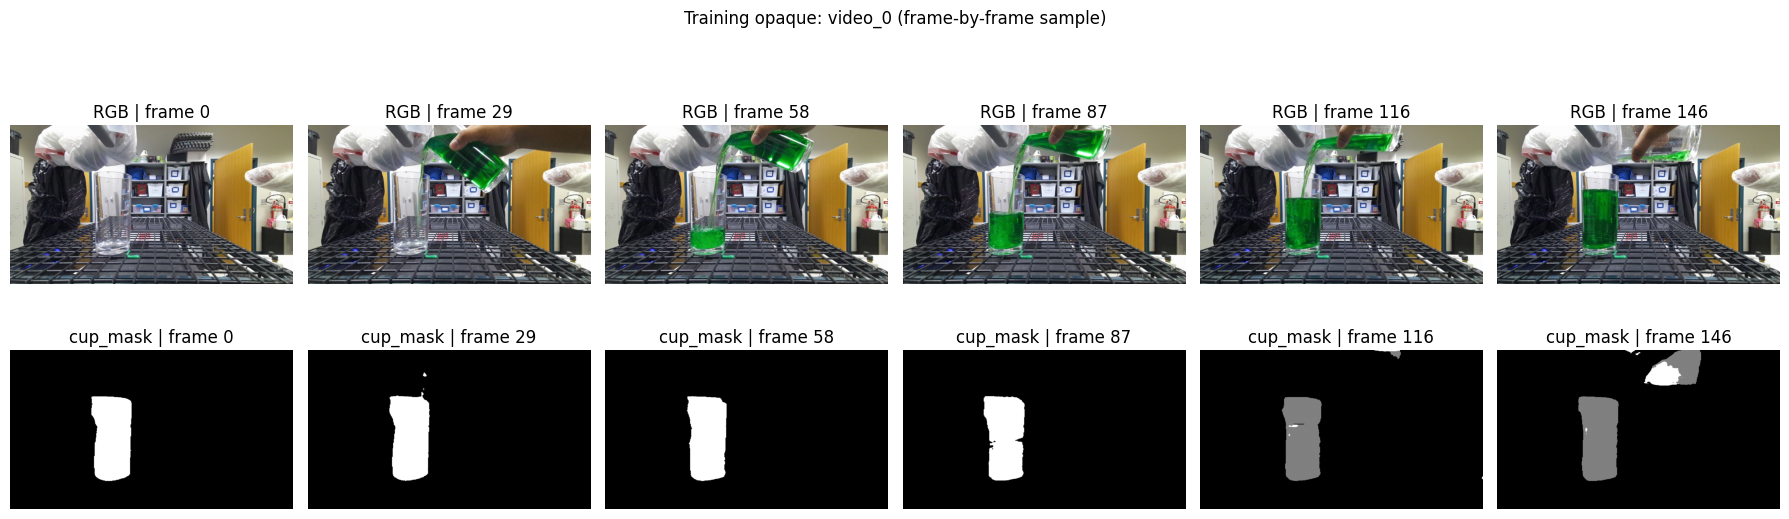

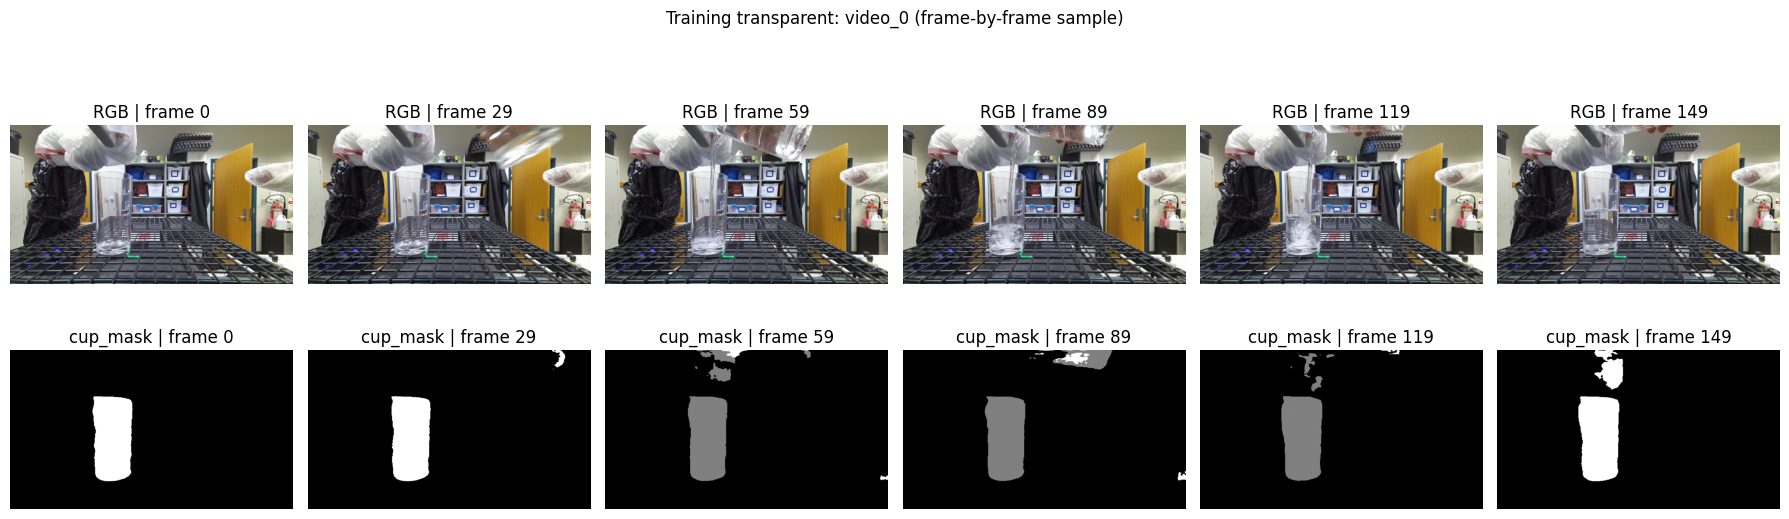

In [6]:
def show_training_video_frames(material: str, video_name: str = 'video_0', n_frames: int = 6):
    assert material in {'opaque', 'transparent'}

    video_dir = TRAIN_ROOT / material / video_name
    mask_dir = TRAIN_ROOT / material / f'{video_name}_cup_masks'

    rgb_paths = sorted(video_dir.glob('rgb_*.jpg'), key=frame_idx_from_name)
    selected = pick_spread(rgb_paths, n=n_frames)

    if not selected:
        print(f'No training RGB frames found in {video_dir}')
        return

    rows, cols = 2, len(selected)
    fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 2.8 * rows))

    for col, rgb_path in enumerate(selected):
        idx = frame_idx_from_name(rgb_path)
        mask_path = mask_dir / f'rgb_{idx}_cup_mask.png'

        rgb = read_img(rgb_path)
        mask = read_img(mask_path)

        items = [('RGB', rgb), ('cup_mask', mask)]
        for row, (name, img) in enumerate(items):
            ax = axes[row, col] if cols > 1 else axes[row]
            if img is None:
                ax.text(0.5, 0.5, 'missing', ha='center', va='center')
            elif img.ndim == 2:
                ax.imshow(img, cmap='gray')
            else:
                ax.imshow(img)
            ax.set_title(f'{name} | frame {idx}')
            ax.axis('off')

    fig.suptitle(f'Training {material}: {video_name} (frame-by-frame sample)', y=1.02)
    plt.tight_layout()
    plt.show()

show_training_video_frames('opaque', 'video_0', n_frames=6)
show_training_video_frames('transparent', 'video_0', n_frames=6)

## Empty-cup reference frames

Training videos also include empty-cup references (`empty_cup_*.jpg`) useful for calibration/background understanding.

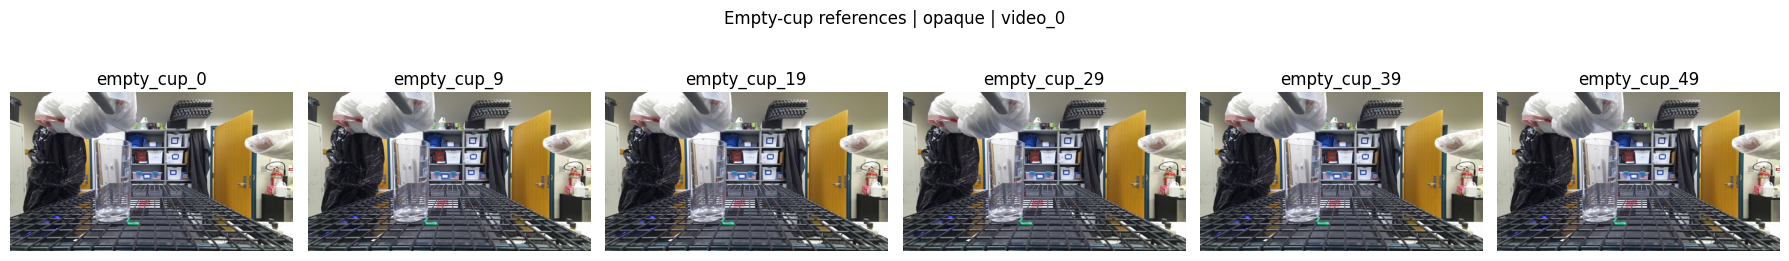

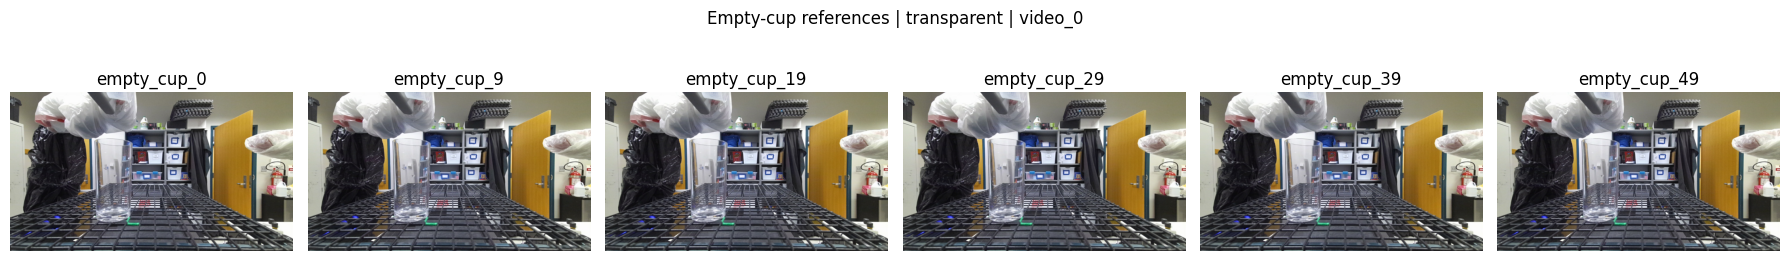

In [7]:
def show_empty_cup_frames(material: str, video_name: str = 'video_0', n_frames: int = 6):
    video_dir = TRAIN_ROOT / material / video_name
    paths = sorted(video_dir.glob('empty_cup_*.jpg'), key=lambda p: int(p.stem.split('_')[-1]))
    selected = pick_spread(paths, n=n_frames)

    if not selected:
        print(f'No empty-cup frames found in {video_dir}')
        return

    cols = len(selected)
    fig, axes = plt.subplots(1, cols, figsize=(3.0 * cols, 2.8))
    if cols == 1:
        axes = [axes]

    for ax, p in zip(axes, selected):
        img = read_img(p)
        if img is not None:
            ax.imshow(img if img.ndim == 3 else img, cmap=None if img.ndim == 3 else 'gray')
        ax.set_title(p.stem)
        ax.axis('off')

    fig.suptitle(f'Empty-cup references | {material} | {video_name}', y=1.02)
    plt.tight_layout()
    plt.show()

show_empty_cup_frames('opaque', 'video_0', n_frames=6)
show_empty_cup_frames('transparent', 'video_0', n_frames=6)

## Takeaways

- The pouring dataset is **video-centric** and naturally consumed frame-by-frame.
- Test videos provide **polygon liquid-mask annotations** via LabelMe-style JSON plus rendered sidecar labels.
- Training videos provide broad **RGB + cup-mask supervision** in both opaque and transparent domains.
- Empty-cup references add useful context for normalization/calibration workflows.

This notebook can be reused as a dataset presentation before model development or benchmarking.